# Multimodal RAG — retrieving from images and video

You already know RAG: chunk your documents, embed them, retrieve the nearest chunks, put them
in the prompt. It works beautifully — right up to the moment the answer is in a **picture**.

Real knowledge bases are full of pictures. The fault-code sticker inside an inverter. The
wiring figure with the torque spec in a callout. The chart where the yield collapsed on
Wednesday. The training video where someone says "wait five minutes before you open the lid".
None of that is text, and none of it survives a text pipeline.

**Today:** the same company, the same questions, four pipelines.

| Part | What we build |
|---|---|
| 1 | Text-only RAG, and exactly where it fails |
| 2 | **Caption and index** — a vision model describes each image once |
| 3 | **Joint embedding (CLIP)** — text and images in one vector space |
| 4 | **Retrieve, then look** — hand the image itself to the model |
| 5 | **Video RAG** — transcripts, frames, and answers with a timestamp |
| 6 | Evaluate all of it, and decide what to use when |

> The company is **Lumio Solar**, a fictional rooftop-solar installer. Field technicians ask
> questions; the knowledge base is four manual pages, ten images and one training video.

In [ ]:
%pip install -q "langchain==1.4.2" "langchain-openai==1.6.2" "langchain-text-splitters==1.1.2" python-dotenv pillow
# Optional, for Part 3 (downloads a ~600 MB model the first time):
# %pip install -q sentence-transformers

In [2]:
import base64, json, os, getpass, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(usecwd=True) or Path.cwd().parent / ".env")
except ImportError:
    pass
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")

# Anaconda 'base' fix (same as the agent notebooks). httpx2 2.12+ decompresses brotli with
# output_buffer_limit=... as a keyword; Anaconda's brotli 1.x rejects kwargs.
try:
    import brotli as _brotli
    from httpx2._decoders import BrotliDecoder as _BrotliDecoder
    _probe = _brotli.Decompressor()
    try:
        _probe.process(b"", output_buffer_limit=1)
    except TypeError:
        _brotli_init = _BrotliDecoder.__init__
        def _brotli_init_compat(self, *args, **kwargs):
            _brotli_init(self, *args, **kwargs)
            _impl = self._decompress
            self._decompress = lambda data, output_buffer_limit=None, **_k: _impl(data)
        _BrotliDecoder.__init__ = _brotli_init_compat
except Exception:
    pass

from IPython.display import Image as IPImage, Markdown, display
from PIL import Image
from langchain.chat_models import init_chat_model
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

MODEL = "openai:gpt-4.1-mini"          # multimodal: it accepts images as well as text
llm = init_chat_model(MODEL, temperature=0)
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

CORPUS = Path.cwd().parent / "corpus" if (Path.cwd() / "src").exists() else Path("../corpus")
CORPUS = CORPUS.resolve()
IMAGES = sorted((CORPUS / "images").glob("*.png"))
DOCS = sorted((CORPUS / "docs").glob("*.md"))
MANIFEST = json.loads((CORPUS / "manifest.json").read_text())

print(f"corpus at {CORPUS}")
print(f"{len(DOCS)} text documents, {len(IMAGES)} images, 1 video")

corpus at /Users/divijbajaj/Library/CloudStorage/OneDrive-Personal/AI_Agents_IndustryCaseStudy/Agentic_AI_Deck/multimodal_rag/corpus
4 text documents, 10 images, 1 video


## A look at what we are working with

Four manual pages of plain text, and ten images. Note what the images *are*: not decoration —
a fault-code sticker, a wiring figure, performance charts, equipment photographs. In a real
field-service knowledge base this is where the specifics live.

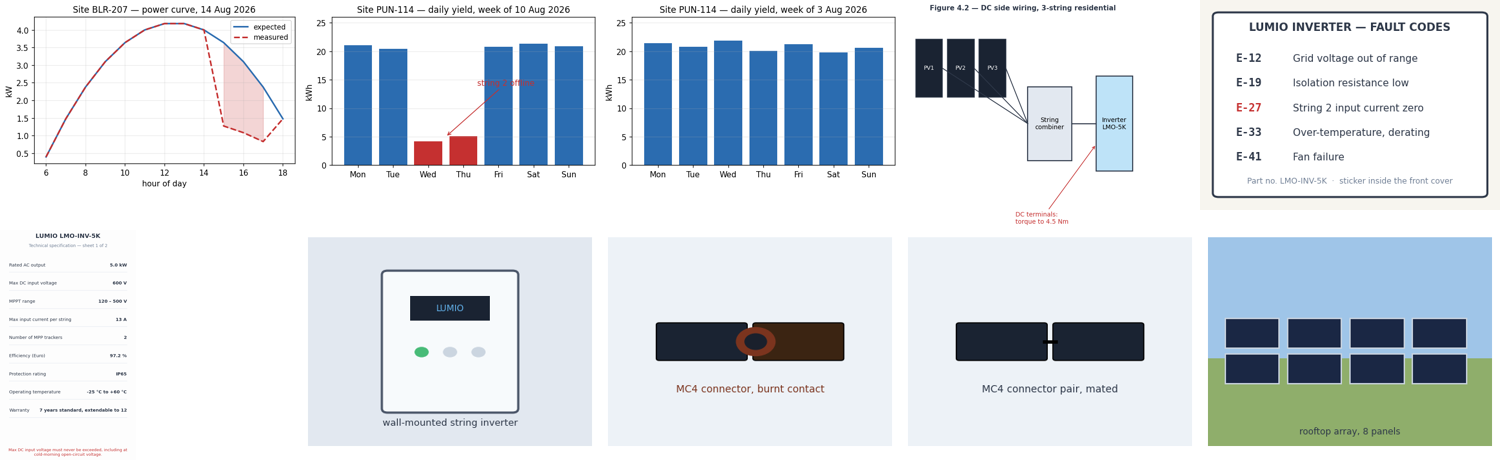

  chart_shading_signature.png
  chart_yield_fault.png
  chart_yield_normal.png
  diagram_dc_wiring.png
  label_fault_codes.png
  page_spec_inverter.png
  photo_inverter_unit.png
  photo_mc4_connector_burnt.png
  photo_mc4_connector_ok.png
  photo_rooftop_array.png


In [3]:
def contact_sheet(paths, cols=5, w=300, h=230):
    sheet = Image.new("RGB", (w * cols, h * ((len(paths) + cols - 1) // cols)), "white")
    for i, p in enumerate(paths):
        im = Image.open(p).convert("RGB")
        im.thumbnail((w, h))
        sheet.paste(im, ((i % cols) * w, (i // cols) * h))
    return sheet


display(contact_sheet(IMAGES))
for p in IMAGES:
    print(" ", p.name)

---
# Part 1 — Text-only RAG, and where it stops

First, ordinary RAG over the four text documents. Nothing new here — this is the pipeline the
class has already built.

In [4]:
text_chunks = RecursiveCharacterTextSplitter(chunk_size=700, chunk_overlap=100).split_documents(
    [Document(page_content=p.read_text(), metadata={"source": p.name}) for p in DOCS])
text_store = InMemoryVectorStore.from_documents(text_chunks, embeddings)
print(f"{len(text_chunks)} text chunks indexed from {len(DOCS)} documents")


def text_rag(question: str, k: int = 3) -> str:
    hits = text_store.similarity_search(question, k=k)
    context = "\n\n".join(f"[{h.metadata['source']}]\n{h.page_content}" for h in hits)
    return llm.invoke(
        "Answer the technician's question using ONLY the context. If the context does not "
        "contain the answer, say so plainly.\n\n"
        f"CONTEXT:\n{context}\n\nQUESTION: {question}").content

4 text chunks indexed from 4 documents


In [5]:
QUESTIONS = [
    "What does inverter fault code E-27 mean?",
    "What torque is specified for the inverter DC terminals?",
    "On which day did site PUN-114's yield collapse, and to what value?",
    "How long must I wait after isolating before opening the inverter lid?",
]

for q in QUESTIONS:
    print("Q:", q)
    print("A:", text_rag(q).strip()[:260], "\n")

Q: What does inverter fault code E-27 mean?


A: The context does not contain the answer. 

Q: What torque is specified for the inverter DC terminals?


A: The context does not contain the specified torque for the inverter DC terminals. 

Q: On which day did site PUN-114's yield collapse, and to what value?


A: The context does not contain the answer. 

Q: How long must I wait after isolating before opening the inverter lid?


A: The context does not contain the answer. 



Four questions a technician would ask on a roof. Text RAG answers **none** of them — and the
useful thing is *why*. Each answer lives somewhere a text pipeline cannot see:

| Question | Where the answer actually is |
|---|---|
| What does E-27 mean? | a photograph of the sticker inside the inverter cover |
| What torque for the DC terminals? | a callout in wiring figure 4.2 |
| When did PUN-114 collapse? | a bar chart |
| How long to wait after isolating? | spoken at 00:22 in a training video |

Notice too that the model behaved well — it said it didn't know rather than inventing. That is
the retrieval doing its job. A worse-tuned pipeline would have guessed, and *that* is the
danger: the documents talk around these topics without containing the specifics.

---
# Part 2 — Strategy A: caption and index

The simplest way to make images searchable is to **turn them into text once**, at indexing
time, with a vision model. You then reuse your entire existing text pipeline.

The cost is one vision call per image, paid once. The risk is that whatever the caption misses
is invisible forever — so the captioning prompt matters more than people expect.

In [6]:
def encode_image(path: Path) -> str:
    """A data URI, which is how an image is passed to a chat model."""
    return f"data:image/png;base64,{base64.b64encode(Path(path).read_bytes()).decode()}"


def ask_with_image(prompt: str, path: Path, model=llm) -> str:
    message = {"role": "user", "content": [
        {"type": "text", "text": prompt},
        {"type": "image_url", "image_url": {"url": encode_image(path)}}]}
    return model.invoke([message]).content


CAPTION_PROMPT = """Describe this image for a search index used by solar field technicians.

Write one dense paragraph. State what kind of asset it is (chart, wiring diagram, equipment
label, specification page, photograph). Then transcribe EVERY number, code, label and unit you
can read, exactly as printed — fault codes, torque values, voltages, dates, site ids, axis
values. If it is a chart, say what it shows and name the notable values. Do not speculate about
anything you cannot see."""

captions = {}
for p in IMAGES:
    captions[p.name] = ask_with_image(CAPTION_PROMPT, p)
    print(f"{p.name:34} {len(captions[p.name]):>4} chars")

chart_shading_signature.png         853 chars


chart_yield_fault.png               610 chars


chart_yield_normal.png              537 chars


diagram_dc_wiring.png               421 chars


label_fault_codes.png               397 chars


page_spec_inverter.png              547 chars


photo_inverter_unit.png             541 chars


photo_mc4_connector_burnt.png       430 chars


photo_mc4_connector_ok.png          479 chars


photo_rooftop_array.png             707 chars


In [7]:
print(captions["label_fault_codes.png"][:600])

This image is a fault code reference chart for a Lumio inverter. It lists five fault codes with their descriptions: E-12 Grid voltage out of range, E-19 Isolation resistance low, E-27 String 2 input current zero (highlighted in red), E-33 Over-temperature, derating, and E-41 Fan failure. At the bottom, it includes the part number "LMO-INV-5K" and a note stating "sticker inside the front cover."


That is the whole trick: the sticker is now **text**, and text is something our existing
retriever understands. Index the captions, keeping a pointer back to the image file.

In [8]:
caption_docs = [Document(page_content=f"{name}\n{cap}",
                         metadata={"source": name, "modality": "image",
                                   "path": str(CORPUS / "images" / name)})
                for name, cap in captions.items()]
multimodal_store = InMemoryVectorStore.from_documents(text_chunks + caption_docs, embeddings)
print(f"{len(text_chunks)} text chunks + {len(caption_docs)} image captions "
      f"= {len(text_chunks) + len(caption_docs)} searchable items")


def caption_rag(question: str, k: int = 4):
    hits = multimodal_store.similarity_search(question, k=k)
    context = "\n\n".join(f"[{h.metadata['source']}]\n{h.page_content}" for h in hits)
    answer = llm.invoke(
        "Answer the technician's question using ONLY the context. Cite the source you used. "
        "If the context does not contain the answer, say so.\n\n"
        f"CONTEXT:\n{context}\n\nQUESTION: {question}").content
    return answer, hits

4 text chunks + 10 image captions = 14 searchable items


In [9]:
for q in QUESTIONS[:3]:
    answer, hits = caption_rag(q)
    print("Q:", q)
    print("   retrieved:", ", ".join(h.metadata["source"] for h in hits))
    print("   A:", answer.strip()[:230], "\n")

Q: What does inverter fault code E-27 mean?
   retrieved: label_fault_codes.png, warranty_and_support.md, photo_inverter_unit.png, page_spec_inverter.png
   A: Inverter fault code E-27 means "String 2 input current zero" (highlighted in red on the fault code reference chart).  
Source: label_fault_codes.png 



Q: What torque is specified for the inverter DC terminals?
   retrieved: diagram_dc_wiring.png, page_spec_inverter.png, warranty_and_support.md, photo_inverter_unit.png
   A: The specified torque for the inverter DC terminals is 4.5 Nm, as indicated by the label next to the connection between the string combiner and the inverter in the wiring diagram (diagram_dc_wiring.png). 



Q: On which day did site PUN-114's yield collapse, and to what value?
   retrieved: chart_yield_fault.png, chart_yield_normal.png, chart_shading_signature.png, maintenance_schedule.md
   A: Site PUN-114's yield collapsed on Wednesday, with the value dropping to approximately 4.3 kWh (and Thursday also low at about 5.1 kWh), as indicated by the annotation "string 2 offline" on the chart for the week of 10 Aug 2026 (ch 



Three of the four questions now answered, from the same vector store, with the same retriever,
because the images were converted into something it could read.

**What this strategy is good at:** documents, charts, labels, diagrams, screenshots — anything
where the meaning is carried by text and structure. It also keeps your stack simple: one index,
one embedding model, no new infrastructure.

**What it is bad at:** *visual* similarity. If a technician photographs a burnt connector and
asks "have we seen this before", a caption search on the words "burnt connector" may work — but
only because the caption happened to use those words. Matching a picture to a picture is a
different problem, and it needs a different tool.

---
# Part 3 — Strategy B: one vector space for text and images (CLIP)

**CLIP** was trained on hundreds of millions of image–caption pairs with one objective: put an
image and its caption close together in the same vector space. The consequence is that you can
embed a *photograph* and a *sentence* with the same model and compare them directly.

That buys two things a caption index cannot do:

- **text → image** search with no captioning step at all, and
- **image → image** search, which is what you want when the query *is* a photograph.

In [10]:
try:
    from sentence_transformers import SentenceTransformer, util
    clip = SentenceTransformer("clip-ViT-B-32")      # ~600 MB on first run
    CLIP_AVAILABLE = True
    print("CLIP loaded:", clip.get_sentence_embedding_dimension(), "dimensions")
except Exception as e:
    CLIP_AVAILABLE = False
    print("CLIP not available — Part 3 will be skipped. Reason:", type(e).__name__, e)
    print("Install with: pip install sentence-transformers")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


CLIP loaded: None dimensions


In [11]:
if CLIP_AVAILABLE:
    clip_images = [Image.open(p).convert("RGB") for p in IMAGES]
    image_vectors = clip.encode(clip_images, convert_to_tensor=True, normalize_embeddings=True,
                                batch_size=8, show_progress_bar=False)
    print("image matrix:", tuple(image_vectors.shape), " (10 images × 512 dimensions)")


def clip_search(query, k=3):
    """query may be a string OR a PIL image — the same function handles both."""
    q = clip.encode([query], convert_to_tensor=True, normalize_embeddings=True,
                    show_progress_bar=False)
    scores = util.cos_sim(q, image_vectors)[0]
    ranked = sorted(zip(IMAGES, scores.tolist()), key=lambda t: -t[1])[:k]
    return [(p.name, round(s, 3)) for p, s in ranked]


if CLIP_AVAILABLE:
    for q in ["a photograph of solar panels on a roof",
              "a burnt electrical connector",
              "a bar chart of daily energy output",
              "an electrical wiring diagram"]:
        print(f"{q:44} -> {clip_search(q)}")

image matrix: (10, 512)  (10 images × 512 dimensions)


a photograph of solar panels on a roof       -> [('photo_rooftop_array.png', 0.239), ('page_spec_inverter.png', 0.21), ('diagram_dc_wiring.png', 0.2)]
a burnt electrical connector                 -> [('photo_mc4_connector_burnt.png', 0.297), ('photo_mc4_connector_ok.png', 0.253), ('label_fault_codes.png', 0.204)]


a bar chart of daily energy output           -> [('chart_yield_normal.png', 0.275), ('photo_rooftop_array.png', 0.269), ('chart_shading_signature.png', 0.261)]
an electrical wiring diagram                 -> [('diagram_dc_wiring.png', 0.298), ('photo_mc4_connector_ok.png', 0.254), ('photo_inverter_unit.png', 0.244)]


Read those four results carefully, because two of them are wrong and that is the lesson.

- **"solar panels on a roof"** and **"a burnt electrical connector"** — correct, and this is
  CLIP at its best: no captions, no vision calls, pure visual semantics.
- **"a bar chart of daily energy output"** — it finds *a* chart, but it cannot tell you *which*
  chart, because the difference between the two is the printed numbers, and CLIP does not read
  text reliably.
- **"an electrical wiring diagram"** — often mis-ranked. Our diagram is schematic and sparse;
  CLIP's training data was photographs and illustrations, not engineering figures.

One more thing, and it catches people out in production:

In [12]:
if CLIP_AVAILABLE:
    print("a photograph of a dog ->", clip_search("a photograph of a dog"))

a photograph of a dog -> [('photo_mc4_connector_ok.png', 0.171), ('photo_rooftop_array.png', 0.17), ('photo_mc4_connector_burnt.png', 0.167)]


There is no dog in this corpus. CLIP returns its three nearest images anyway, with respectable
scores. **Similarity is always relative; it has no concept of "nothing here matches".** If you
use CLIP for retrieval you must set a score threshold and handle the empty case yourself —
exactly like a vector search over text, but the failure is less obvious because an image
*looks* like an answer.

## Where CLIP genuinely wins: the query is a photograph

A technician photographs a component on site and asks "what is this, and have we seen it
before?" No words involved.

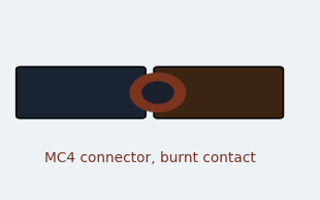

visually nearest assets: [('photo_mc4_connector_burnt.png', 0.888), ('photo_mc4_connector_ok.png', 0.794), ('photo_rooftop_array.png', 0.732)]


In [13]:
if CLIP_AVAILABLE:
    query_photo = Image.open(CORPUS / "images" / "photo_mc4_connector_burnt.png").convert("RGB")
    # pretend this is a fresh photo from the field: crop and shrink it so it is not identical
    w, h = query_photo.size
    query_photo = query_photo.crop((int(w*0.15), int(h*0.2), int(w*0.9), int(h*0.85))).resize((320, 200))
    display(query_photo)
    print("visually nearest assets:", clip_search(query_photo, k=3))

The altered photograph still retrieves the burnt-connector asset first. A caption index cannot
do this at all without first captioning the query image — which is another vision call, and a
lossy one.

---
# Part 4 — Strategy C: retrieve, then actually look

Captions are a *summary*. Whatever the caption left out is gone. For questions that need
detail — "read the third row of that table", "what is the value at 15:00" — the robust pattern
is:

> **retrieve the image, then put the image itself in front of the model.**

The retriever decides *which* picture; the vision model reads it at answer time.

In [14]:
def multimodal_rag(question: str, k: int = 4, show: bool = True) -> str:
    """Retrieve across text and image captions, then let the model look at any image it got."""
    hits = multimodal_store.similarity_search(question, k=k)
    text_bits, image_paths = [], []
    for h in hits:
        if h.metadata.get("modality") == "image":
            image_paths.append(Path(h.metadata["path"]))
        else:
            text_bits.append(f"[{h.metadata['source']}]\n{h.page_content}")

    content = [{"type": "text", "text":
                "You are a Lumio field-support assistant. Answer the technician's question using "
                "ONLY the context and the attached images. Read values directly off any chart, "
                "label or figure. Cite the file name you used. If the answer is not there, say so."
                + (f"\n\nTEXT CONTEXT:\n" + "\n\n".join(text_bits) if text_bits else "")
                + f"\n\nATTACHED IMAGES: {[p.name for p in image_paths]}"
                + f"\n\nQUESTION: {question}"}]
    for p in image_paths[:3]:                       # cap: images are the expensive part
        content.append({"type": "image_url", "image_url": {"url": encode_image(p)}})

    answer = llm.invoke([{"role": "user", "content": content}]).content
    if show and image_paths:
        print("looked at:", ", ".join(p.name for p in image_paths[:3]))
    return answer

In [15]:
for q in QUESTIONS[:3]:
    print("Q:", q)
    print("A:", multimodal_rag(q).strip()[:300], "\n")

Q: What does inverter fault code E-27 mean?


looked at: label_fault_codes.png, photo_inverter_unit.png, page_spec_inverter.png
A: The inverter fault code E-27 means "String 2 input current zero." This information is from the file labeled "label_fault_codes.png." 

Q: What torque is specified for the inverter DC terminals?


looked at: diagram_dc_wiring.png, page_spec_inverter.png, photo_inverter_unit.png
A: The specified torque for the inverter DC terminals is 4.5 Nm, as shown in the diagram_dc_wiring.png image. 

Q: On which day did site PUN-114's yield collapse, and to what value?


looked at: chart_yield_fault.png, chart_yield_normal.png, chart_shading_signature.png
A: Site PUN-114's yield collapsed on Wednesday of the week of 10 Aug 2026, dropping to about 4.3 kWh. It remained low on Thursday at about 5.1 kWh before recovering on Friday. This is shown in the "chart_yield_fault.png" image. 



Compare this with Part 2. The caption pipeline answered from a *description* of the chart; this
one answered from the **chart**. When the caption is good, both work. When the question needs a
detail the caption skipped, only this one can recover — and it costs an image in the prompt
every time you ask, rather than once at indexing.

A practical compromise used in production: **index captions, attach images.** Captions make
retrieval cheap and searchable; attaching the retrieved image makes the answer accurate. That is
exactly what `multimodal_rag` above does.

---
# Part 5 — Video

A video is not one object. It is two aligned streams: **what was said** and **what was shown**.
Both are retrievable, and the unit of retrieval is a *time range*, not a file.

Our training video ships with a transcript. In production you would generate one with Whisper
or a managed speech-to-text service; the shape of what follows does not change.

In [16]:
VIDEO = CORPUS / "video"
transcript = json.loads((VIDEO / "inverter_replacement_transcript.json").read_text())
keyframes = sorted((VIDEO / "keyframes").glob("*.png"))

print(f"{len(transcript)} transcript segments, {len(keyframes)} keyframes")
for seg in transcript[:4]:
    print(f"  [{seg['start_s']:>3}s] {seg['text'][:88]}")

9 transcript segments, 9 keyframes
  [  0s] Welcome to training module seven, replacing a Lumio string inverter.
  [  6s] Step one. Switch off the AC isolator and lock it off before you touch anything.
  [ 14s] Step two. Open the DC isolator at the string combiner.
  [ 22s] Step three, and this is the one people skip. Wait five minutes after isolating before yo


### Chunking a transcript

Transcript segments are short, so embedding each one alone retrieves poorly — too little
context. Group neighbouring segments into overlapping windows and keep the **start time** of
each window, which is what the citation will point at.

In [17]:
def window_transcript(segments, size=3, stride=2):
    windows = []
    for i in range(0, len(segments), stride):
        group = segments[i:i + size]
        if not group:
            continue
        windows.append(Document(
            page_content=" ".join(s["text"] for s in group),
            metadata={"source": "inverter_replacement.mp4", "modality": "video",
                      "start_s": group[0]["start_s"], "end_s": group[-1]["start_s"]}))
    return windows


video_windows = window_transcript(transcript)
video_store = InMemoryVectorStore.from_documents(video_windows, embeddings)
for w in video_windows[:3]:
    print(f"[{w.metadata['start_s']:>3}s - {w.metadata['end_s']:>3}s] {w.page_content[:80]}...")

[  0s -  14s] Welcome to training module seven, replacing a Lumio string inverter. Step one. S...
[ 14s -  32s] Step two. Open the DC isolator at the string combiner. Step three, and this is t...
[ 32s -  52s] Step four. Confirm zero volts across the DC terminals with a meter rated for the...


In [18]:
def nearest_keyframe(t: int) -> Path:
    """The frame a viewer would see at time t — our keyframes are one per scene."""
    times = [int(p.stem[1:]) for p in keyframes]
    best = max([x for x in times if x <= t], default=times[0])
    return next(p for p in keyframes if int(p.stem[1:]) == best)


def video_rag(question: str, k: int = 2) -> str:
    hits = video_store.similarity_search(question, k=k)
    top = hits[0]
    frame = nearest_keyframe(top.metadata["start_s"])
    context = "\n\n".join(
        f"[{h.metadata['start_s']}s-{h.metadata['end_s']}s] {h.page_content}" for h in hits)
    content = [{"type": "text", "text":
                "Answer using the video transcript below and the attached frame from the video. "
                "End with the timestamp range the information comes from, as (mm:ss-mm:ss), "
                "taken from the segment headers.\n\n"
                f"TRANSCRIPT (each segment is headed with its start time):\n{context}\n\n"
                f"QUESTION: {question}"},
               {"type": "image_url", "image_url": {"url": encode_image(frame)}}]
    answer = llm.invoke([{"role": "user", "content": content}]).content
    t = top.metadata["start_s"]
    print(f"best segment: {t//60:02d}:{t%60:02d}   frame: {frame.name}")
    display(IPImage(filename=str(frame), width=380))
    return answer

best segment: 00:14   frame: t014.png


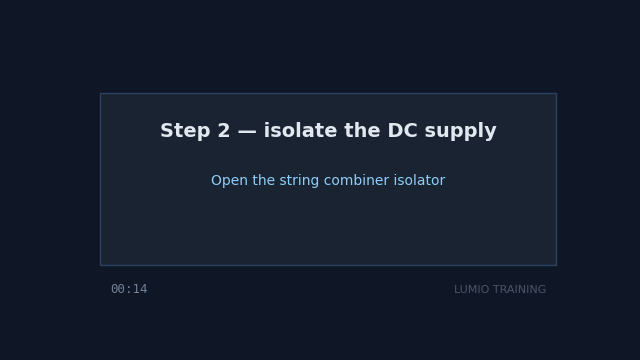

You must wait five minutes after isolating before opening the inverter lid. This is important because the capacitors inside stay charged and need time to discharge safely. (14s-32s)


In [19]:
print(video_rag("How long must I wait after isolating before opening the inverter lid?"))

The fourth question — the one no text or image pipeline could touch — answered, with a
timestamp a technician can jump to.

Two things to notice in that pipeline:

1. **The transcript did the retrieval, the frame supported the answer.** Speech is usually the
   higher-signal stream for "where is this discussed"; frames are better for "show me".
2. **The citation is a time, not a document.** That is the correct unit for video, and it is
   what makes the answer verifiable.

A caveat on precision: our windows are three segments wide, so the citation points at the
*window*, not the exact sentence. Narrow windows give tighter citations and worse retrieval;
wide windows do the opposite. Exercise 5 asks you to find the trade-off for this video.

### When frames do the retrieving instead

If the question is visual — *"find the part of the video where the torque driver appears"* —
embed the frames with CLIP and search those instead. Same idea as Part 3, applied to a
sequence of stills.

In [20]:
if CLIP_AVAILABLE:
    frame_imgs = [Image.open(p).convert("RGB") for p in keyframes]
    frame_vecs = clip.encode(frame_imgs, convert_to_tensor=True, normalize_embeddings=True,
                             show_progress_bar=False)
    q = clip.encode(["a slide about torque settings"], convert_to_tensor=True,
                    normalize_embeddings=True, show_progress_bar=False)
    scores = util.cos_sim(q, frame_vecs)[0].tolist()
    ranked = sorted(zip(keyframes, scores), key=lambda t: -t[1])[:3]
    for p, sc in ranked:
        t = int(p.stem[1:])
        print(f"  {t//60:02d}:{t%60:02d}  score {sc:.3f}  {p.name}")

  01:02  score 0.307  t062.png
  01:12  score 0.261  t072.png
  00:06  score 0.252  t006.png


---
# Part 6 — Does it actually work? Measure it.

Four pipelines, one question set. For each question we know which asset holds the answer, so we
can score **retrieval** (did the right asset come back) separately from **answering** (was the
final answer right). Those fail for different reasons and need different fixes.

In [21]:
from pydantic import BaseModel, Field

EVAL = [
    # (question, asset that holds the answer, what a correct answer must contain)
    ("What does inverter fault code E-27 mean?", "label_fault_codes.png", "string 2 input current is zero"),
    ("What torque is specified for the inverter DC terminals?", "diagram_dc_wiring.png", "4.5 Nm"),
    ("On which day did site PUN-114's yield collapse, and to what value?", "chart_yield_fault.png",
     "Wednesday, roughly 4 kWh (anything from 4 to 4.5 counts — it is read off a chart)"),
    ("What is the maximum DC input voltage of the LMO-INV-5K?", "page_spec_inverter.png", "600 V"),
    ("How long is the standard warranty on the inverter?", "page_spec_inverter.png", "7 years"),
    ("What does afternoon shading look like on the power curve?", "chart_shading_signature.png",
     "a dip between roughly 15:00 and 17:00, not a whole-day loss"),
    ("What must I do before opening any enclosure?", "safety_rules.md",
     "isolate AC, then DC, then confirm zero volts with a meter"),
    ("How often should DC connectors be thermally scanned?", "maintenance_schedule.md", "annually"),
]


class Verdict(BaseModel):
    correct: bool = Field(description="Does the answer contain the required fact?")
    why: str = Field(description="One short sentence")


judge = llm.with_structured_output(Verdict)


def retrieved_names(question, store, k=4):
    return [h.metadata["source"] for h in store.similarity_search(question, k=k)]

In [22]:
rows = []
for question, gold_asset, must_contain in EVAL:
    got_text = retrieved_names(question, text_store)
    got_mm = retrieved_names(question, multimodal_store)
    a_text = text_rag(question)
    a_mm = multimodal_rag(question, show=False)
    v_text = judge.invoke(f"REQUIRED FACT: {must_contain}\nANSWER: {a_text}\nIs the required fact present?")
    v_mm = judge.invoke(f"REQUIRED FACT: {must_contain}\nANSWER: {a_mm}\nIs the required fact present?")
    rows.append({"question": question[:46], "gold": gold_asset,
                 "text_hit": gold_asset in got_text, "mm_hit": gold_asset in got_mm,
                 "text_ok": v_text.correct, "mm_ok": v_mm.correct})

hdr = f"{'question':<48} {'gold asset':<28} {'retr:text':<10} {'retr:mm':<9} {'ans:text':<9} {'ans:mm'}"
print(hdr); print("-" * len(hdr))
for r in rows:
    print(f"{r['question']:<48} {r['gold']:<28} "
          f"{str(r['text_hit']):<10} {str(r['mm_hit']):<9} {str(r['text_ok']):<9} {r['mm_ok']}")
n = len(rows)
print("-" * len(hdr))
print(f"retrieval  text-only {sum(r['text_hit'] for r in rows)}/{n}    multimodal {sum(r['mm_hit'] for r in rows)}/{n}")
print(f"answers    text-only {sum(r['text_ok'] for r in rows)}/{n}    multimodal {sum(r['mm_ok'] for r in rows)}/{n}")

question                                         gold asset                   retr:text  retr:mm   ans:text  ans:mm
-------------------------------------------------------------------------------------------------------------------
What does inverter fault code E-27 mean?         label_fault_codes.png        False      True      False     True
What torque is specified for the inverter DC t   diagram_dc_wiring.png        False      True      False     True
On which day did site PUN-114's yield collapse   chart_yield_fault.png        False      True      False     True
What is the maximum DC input voltage of the LM   page_spec_inverter.png       False      True      False     True
How long is the standard warranty on the inver   page_spec_inverter.png       False      True      False     True
What does afternoon shading look like on the p   chart_shading_signature.png  False      True      False     True
What must I do before opening any enclosure?     safety_rules.md              True  

Split the two scores apart whenever you evaluate RAG. A wrong answer with the right document
retrieved is a *prompting* problem. A wrong answer with the wrong document retrieved is a
*retrieval* problem. Fixing the wrong one is the most common waste of a week.

---
# Choosing a strategy

| | Caption and index | Joint embedding (CLIP) | Retrieve, then look |
|---|---|---|---|
| Indexing cost | one vision call per image | one cheap local embedding | none beyond the index you already have |
| Query cost | normal text RAG | very cheap | an image in every prompt |
| Reads text in images | yes, as well as the captioner did | no, unreliable | yes, at full detail |
| Image-as-query | no | **yes** | no |
| Visual similarity | no | **yes** | no |
| New infrastructure | none | an image embedding model | none |
| Best for | documents, charts, labels, screenshots | photographs, "find one like this" | detail questions, final answers |

**The sensible default for a document-heavy knowledge base** is caption-and-index for retrieval,
plus attaching the retrieved image to the answering prompt. Add CLIP when users will search
*with* pictures or by visual similarity.

## Pitfalls worth remembering

- **The caption is the ceiling.** Anything the captioner omitted is unfindable. Caption with a
  prompt that demands numbers, codes and labels verbatim — ours does, and that is why E-27 is
  retrievable.
- **Similarity has no zero.** Both CLIP and text embeddings always return something. Threshold
  the score and handle "no good match" explicitly.
- **Images dominate the context budget.** A single image can cost as much as a page of text.
  Cap how many you attach — we cap at three.
- **Charts are read, not recalled.** A model asked about a value it cannot see will often invent
  a plausible one. Attach the chart, and ask it to state the value it read.
- **Video needs both streams.** Transcript for "where is this discussed", frames for "show me".
  Retrieve a time range, cite the timestamp.
- **Resolution matters.** Downscaling a dense page to save tokens is the usual cause of
  "the model misread the table".

---
## Exercises

**1. Break the caption.** Re-caption the images with a lazy prompt — just "describe this image".
Rerun the Part 2 questions. How many still work, and which fail first?

**2. Threshold CLIP.** `clip_search` always returns three results. Add a minimum score and
return "no visual match" below it. What threshold separates the dog query from the real ones?

**3. Add an asset.** Create a new image (a photo, a chart, anything) with a fact that exists
nowhere else, caption it, index it, and ask a question only it can answer.

**4. Image-as-query, end to end.** Build `answer_from_photo(image)` that CLIP-retrieves the
nearest asset, then asks the vision model what the component is and what to do about it.

**5. Finer video chunks.** Change the transcript window from 3 segments to 1, and to 6. What
happens to retrieval of the five-minute rule, and why?

**6. Cost it.** Count the vision calls and tokens for each strategy over the 8 evaluation
questions. At 10,000 images, which strategy do you choose and what changes?